<p class="lead">A machine-learning engineer who is handed a messy CSV knows the first rule: the model is only as good as the table it learns from. Cheminformatics has exactly the same rule, with sharper teeth. Public bioactivity data — the numbers that say "this molecule inhibits that protein this strongly" — is pooled from thousands of laboratories, decades of papers and several unit conventions, and it arrives duplicated, censored, mislabelled, salted, mixed and occasionally not even a molecule. This unit is a complete, auditable pipeline that turns one such raw export into a dataset you could defend in a review: every transformation is justified by the chemistry it encodes, and <em>every record that is dropped is counted and explained</em>. The slides are a map; this notebook is the territory — run every cell and read its output before moving on.</p>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Explain why the same compound can have many different reported potencies, and what that means for a model.</li>
<li>Harmonise activity units and define and compute pIC50 carefully, including the µg/mL case that needs a molecular weight.</li>
<li>Recognise censored ("&gt;", "&lt;") measurements, say what they mean physically, and choose a defensible policy for them.</li>
<li>Deduplicate and aggregate replicate measurements of one structure, and relate the residual scatter to the known experimental uncertainty of public data.</li>
<li>Remove salts, mixtures and inorganic/organometallic records on principled grounds, quantifying each drop.</li>
<li>Choose an activity threshold for classification and see how that single choice moves the class balance and a downstream metric.</li>
<li>Produce a documented, reproducible, QSAR-ready dataset with a one-page data sheet, and state its limitations honestly.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Green <strong>chemistry boxes</strong> define each chemical term the first time it appears, usually with an analogy a programmer already has. The notebook attempts to fetch a small, real slice of public bioactivity data when it is run with network access; so that the lesson is fully reproducible and every dropped record is traceable, the quantified pipeline runs on a <strong>bundled, deliberately messy sample</strong> that contains one example of every defect. Read linearly once; then re-run cells while changing one thing — a threshold, an aggregation rule — and watch the numbers move. The only library you must install in Colab is RDKit (<code>!pip install rdkit</code>); the rest are already there.</p></div>

In [1]:
# Setup. In Google Colab, run once:  !pip install rdkit
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import rdkit
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors, rdMolDescriptors, inchi
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem import rdFingerprintGenerator
from rdkit.DataStructs import ConvertToNumpyArray
rdkit.RDLogger.DisableLog("rdApp.*")          # silence RDKit parsing/valence logs in this teaching notebook
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
PIPE = []    # running log of (stage, n_records, note) used to draw the curation funnel at the end
print("RDKit", rdkit.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

RDKit 2026.03.4 | pandas 3.0.3 | numpy 2.4.6


## 1. Why curation decides the result

Before any descriptor, any fingerprint, any model, there is a table of measurements. In cheminformatics that table is almost never clean, and the classic study of the problem — Fourches, Muratov and Tropsha's <em>Trust, but verify</em><sup class="c"><a href="#r1">[1]</a></sup> — showed that even widely used, "curated" datasets contain a sobering fraction of wrong structures, wrong salts and duplicated or inconsistent records, and that these errors propagate directly into model statistics. The follow-up practical guide<sup class="c"><a href="#r4">[4]</a></sup> and independent audits of database error rates<sup class="c"><a href="#r3">[3]</a></sup> reached the same conclusion: curation is not housekeeping you do if time permits, it is the step that most determines whether a model learns chemistry or learns noise. The discipline's best-practice guidelines put data curation first for exactly this reason,<sup class="c"><a href="#r13">[13]</a></sup> and its methodological reviews return to data quality as the precondition for everything else.<sup class="c"><a href="#r12">[12]</a></sup>

The reason the stakes are high is that errors in bioactivity data are not random noise that averages out. A single mis-recorded unit can make a weak compound look a thousandfold potent; a duplicate that survives into both the training and the test set manufactures an illusion of predictive skill; a salt counter-ion left attached changes a molecule's computed properties. A computer scientist can read this unit as a study in data cleaning where the schema is chemistry: the join keys are molecular structures (which must be canonicalised before they can be compared), the units are physical (and must be converted with care), and some rows are not data at all but artefacts of how an experiment was reported.

<div class="box bridge"><h4>Chemistry box — target, assay, potency</h4>
<p>A <strong>target</strong> is the biomolecule — usually a protein — whose behaviour a drug is meant to change; here our running target is a protein kinase, an enzyme that switches other proteins on by attaching a phosphate group. An <strong>assay</strong> is a laboratory experiment that measures how strongly a compound affects the target; think of it as one noisy measurement function, with its own reagents, readout and error bars. <strong>Potency</strong> is how little compound you need to get an effect: more potent means a smaller dose does the job. The number we will clean is a potency, and the first thing to internalise is that it is the output of a physical experiment, not a ground truth.</p></div>

<div class="box bridge"><h4>Chemistry box — IC50, Ki and EC50</h4>
<p>Three potency numbers dominate public data. <strong>IC50</strong> is the concentration of a compound that reduces the target's activity by half (I for "inhibitory"); lower IC50 means more potent. <strong>Ki</strong> is a binding-affinity constant from the same family, measured a different way; <strong>EC50</strong> is the concentration giving half of a maximal <em>effect</em> in a functional assay. They are related but not interchangeable: mixing them is one of the curation decisions this unit treats explicitly. All three are concentrations, so they carry units — and units are where we begin.</p></div>

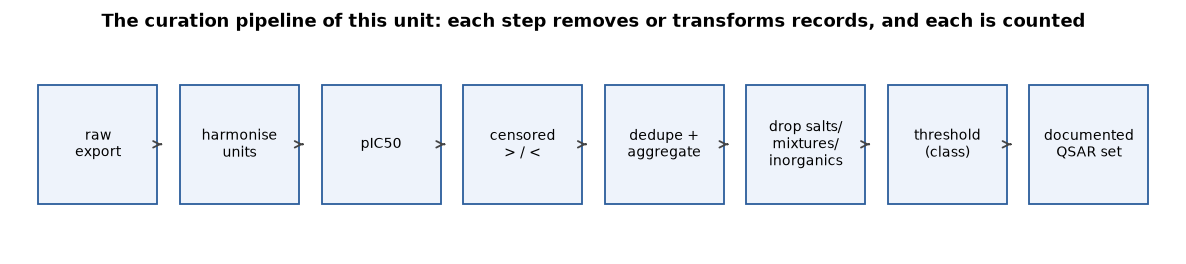

In [2]:
# A conceptual map of the pipeline this unit builds (drawn, not an external image).
fig, ax = plt.subplots(figsize=(9.2, 2.1))
steps = ["raw\nexport", "harmonise\nunits", "pIC50", "censored\n> / <", "dedupe +\naggregate",
         "drop salts/\nmixtures/\ninorganics", "threshold\n(class)", "documented\nQSAR set"]
x = np.arange(len(steps))
for xi, s in zip(x, steps):
    ax.add_patch(plt.Rectangle((xi-0.42, -0.5), 0.84, 1.0, fc="#eef3fb", ec="#2b5d9b"))
    ax.text(xi, 0, s, ha="center", va="center", fontsize=7.6)
    if xi < len(steps)-1:
        ax.annotate("", xy=(xi+0.45, 0), xytext=(xi+0.42, 0), arrowprops=dict(arrowstyle="->", color="#444"))
ax.set_xlim(-0.6, len(steps)-0.4); ax.set_ylim(-0.9, 0.9); ax.axis("off")
ax.set_title("The curation pipeline of this unit: each step removes or transforms records, and each is counted")
fig.tight_layout()

<p class="caption"><b>Figure 1.</b> The pipeline. Reading left to right, a raw export is harmonised to one unit, converted to the pIC50 scale, screened for censored values, deduplicated and replicate-aggregated by chemical structure, cleaned of non-drug records (salts, mixtures, inorganics), and finally thresholded into active/inactive classes — ending as a documented dataset. The whole of this unit is these eight boxes, and the one discipline that ties them together is that <em>every record leaving the pipeline is counted</em>.</p>

## 2. The raw bioactivity slice and why it is messy

Public bioactivity lives in a handful of large resources. <strong>ChEMBL</strong><sup class="c"><a href="#r5">[5]</a></sup> is the one we use: a manually curated database of compounds, assays and measured activities extracted from the medicinal-chemistry literature, first described in 2012<sup class="c"><a href="#r15">[15]</a></sup> and now spanning millions of activity records, with a companion programme to let depositors add data directly.<sup class="c"><a href="#r6">[6]</a></sup> Its data model is a chain: a <em>target</em> (identified by a ChEMBL target ID, often linked to a UniProt protein) is probed by one or more <em>assays</em>, and each assay yields <em>activity</em> rows, one per measurement, carrying a standard type (IC50, Ki…), a standard relation ("=", "&gt;", "&lt;"), a standard value and standard units. Related resources — PubChem, BindingDB<sup class="c"><a href="#r25">[25]</a></sup> and others — use the same shape with different identifiers. ChEMBL already does substantial curation on deposit,<sup class="c"><a href="#r16">[16]</a></sup> which is exactly why the <em>residual</em> mess is instructive: it is the mess that survives professional curation.

The cell below attempts to fetch a small, real slice from the ChEMBL REST web service (a protein kinase target) so you can see the live data model. It is wrapped in a timeout and a try/except: if the network is unavailable the notebook says so and proceeds with the bundled sample, so the build never hangs. We only read the <em>shape</em> of the live slice here — the distribution of units and relations — because those are exactly the defects we are about to fix. Open teaching resources such as the TeachOpenCADD talktorials walk through this kind of programmatic data acquisition in detail.<sup class="c"><a href="#r24">[24]</a></sup>

In [3]:
# Attempt a live ChEMBL fetch to show the real data model; fall back silently if offline.
import urllib.request, json
def fetch_chembl_ic50(target="CHEMBL203", n=300, timeout=8):
    url = (f"https://www.ebi.ac.uk/chembl/api/data/activity.json?"
           f"target_chembl_id={target}&standard_type=IC50&limit={n}")
    with urllib.request.urlopen(url, timeout=timeout) as r:
        return pd.DataFrame(json.load(r)["activities"])
try:
    live = fetch_chembl_ic50()
    units_live = live["standard_units"].value_counts().head(5).to_dict()
    rels_live = live["standard_relation"].value_counts().to_dict()
    print(f"live ChEMBL slice fetched: {len(live)} IC50 rows for target CHEMBL203 (an EGFR kinase)")
    print("most common units in the live slice:", units_live)
    print("relations present in the live slice:", rels_live)
except Exception as e:
    live = None
    print(f"live fetch unavailable ({type(e).__name__}); proceeding with the bundled sample below")

live ChEMBL slice fetched: 300 IC50 rows for target CHEMBL203 (an EGFR kinase)
most common units in the live slice: {'nM': 300}
relations present in the live slice: {'=': 223, '>': 59}


When the fetch succeeds you will see that even a few hundred rows for a single target already contain more than one unit and more than one relation — some values are not "=" but "&gt;" or "&lt;". That heterogeneity is the norm, not the exception, and it is why the rest of the unit exists. Whether or not the fetch succeeded, we now switch to a bundled sample that was constructed to contain exactly one clear example of every defect, so that the counts below are identical every time the notebook runs.

The bundled sample imitates a ChEMBL activity export for a kinase target. The molecules are real kinase inhibitors, but the potency values and the record-level defects (duplicate rows, mixed units, censoring, a salt, a mixture, an inorganic, a mass-concentration unit, a percent-inhibition row) are <strong>synthetic and inserted for teaching</strong> — they are not literal database readings. The next cell generates it deterministically with a fixed random seed so every replicate and every dropped record is reproducible.

In [4]:
# Ten real kinase inhibitors with a synthetic "true" pIC50; all values/defects are fabricated for teaching.
base = [  # (compound_id, name, SMILES, 'true' pIC50)
 ("CPD-01","gefitinib", "COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1", 8.1),
 ("CPD-02","erlotinib", "C#Cc1cccc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)c1", 7.7),
 ("CPD-03","afatinib",  "CN(C)C/C=C/C(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OC1CCOC1", 8.5),
 ("CPD-04","lapatinib", "CS(=O)(=O)CCNCc1ccc(-c2ccc3ncnc(Nc4ccc(OCc5cccc(F)c5)c(Cl)c4)c3c2)o1", 7.2),
 ("CPD-05","vandetanib","COc1cc2ncnc(Nc3ccc(Br)cc3F)c2cc1OCC1CCN(C)CC1", 6.6),
 ("CPD-06","sunitinib", r"CCN(CC)CCNC(=O)c1c(C)[nH]c(/C=C2\C(=O)Nc3ccc(F)cc32)c1C", 5.9),
 ("CPD-07","sorafenib", "CNC(=O)c1cc(Oc2ccc(NC(=O)Nc3ccc(Cl)c(C(F)(F)F)c3)cc2)ccn1", 5.4),
 ("CPD-08","imatinib",  "Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cccnc2)n1", 5.0),
 ("CPD-09","dasatinib", "Cc1nc(Nc2ncc(s2)C(=O)Nc2c(C)cccc2Cl)cc(n1)N1CCN(CCO)CC1", 4.8),
 ("CPD-10","pazopanib", "Cc1ccc(Nc2nccc(N(C)c3ccc4c(C)n(C)nc4c3)n2)cc1S(N)(=O)=O", 5.2),
]
print(len(base), "distinct real compounds; 'true' pIC50 range",
      f"{min(b[3] for b in base):.1f}-{max(b[3] for b in base):.1f} (synthetic)")

10 distinct real compounds; 'true' pIC50 range 4.8-8.5 (synthetic)


In [5]:
# Expand to a messy per-measurement export: replicates, mixed units, censoring at the assay's limits.
rng = np.random.default_rng(0)
assays = ["ASSAY-A1", "ASSAY-A2", "ASSAY-A3", "ASSAY-A4"]
def sig4(x): return float(f"{x:.4g}")
rows = []
for cid, name, smi, p in base:
    for _ in range(int(rng.integers(2, 6))):              # 2-5 replicate measurements each
        pm = p + rng.normal(0, 0.35)                      # measurement noise ~0.35 log units
        ic50_nM = 10 ** (9 - pm)
        typ = "IC50" if rng.random() > 0.15 else "Ki"     # a few Ki rows -> type heterogeneity
        rel, val, unit = "=", ic50_nM, "nM"
        u = rng.random()
        if u < 0.25:   val, unit = ic50_nM / 1e3, "uM"    # a quarter reported in micromolar
        elif u < 0.30: val, unit = ic50_nM / 1e9, "M"     # a few in molar
        if ic50_nM > 10000: rel, val, unit = ">", 10000, "nM"   # above the 10 uM assay ceiling
        elif ic50_nM < 1.0: rel, val, unit = "<", 1.0, "nM"     # below the 1 nM floor
        rows.append([cid, name, smi, typ, rel, sig4(val) if unit != "M" else val, unit, rng.choice(assays)])
print("generated", len(rows), "replicate measurement rows from", len(base), "compounds")

generated 37 replicate measurement rows from 10 compounds


In [6]:
# Append one clear example of every record-level defect a real export contains.
extra = [
 ("CPD-01","gefitinib (HCl salt)",   "COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1.Cl","IC50","=",7.5,"nM","ASSAY-A2"),
 ("CPD-02","erlotinib (exact dup)",  "C#Cc1cccc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)c1",        "IC50","=",20.0,"nM","ASSAY-A1"),
 ("CPD-03","afatinib (left-censored)","CN(C)C/C=C/C(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OC1CCOC1","IC50","<",1.0,"nM","ASSAY-A4"),
 ("CPD-11","aspirin + salicylate",   "CC(=O)Oc1ccccc1C(=O)O.OC(=O)c1ccccc1O",             "IC50","=",120000.0,"nM","ASSAY-A3"),
 ("CPD-12","cisplatin (inorganic)",  "N.N.Cl[Pt]Cl",                                      "IC50","=",8000.0,"nM","ASSAY-A1"),
 ("CPD-13","paracetamol (no value)", "CC(=O)Nc1ccc(O)cc1",                                "IC50","=",np.nan,"nM","ASSAY-A4"),
 ("CPD-14","ibuprofen (mass conc.)", "CC(C)Cc1ccc(C(C)C(=O)O)cc1",                        "IC50","=",2.5,"ug.mL-1","ASSAY-A2"),
 ("CPD-15","benzoic acid (% only)",  "O=C(O)c1ccccc1",                                    "IC50","=",45.0,"%","ASSAY-A3"),
]
cols = ["compound_id","name","smiles","standard_type","standard_relation","standard_value","standard_units","assay_id"]
raw = pd.DataFrame(rows + extra, columns=cols)
raw.insert(0, "record_id", [f"R{i:03d}" for i in range(len(raw))])
PIPE.append(("raw export", len(raw), "every measurement row as received"))
print("raw export:", len(raw), "records,", raw.compound_id.nunique(), "distinct compound_ids")
raw.head(6)

raw export: 45 records, 15 distinct compound_ids


,record_id,compound_id,name,smiles,standard_type,standard_relation,standard_value,standard_units,assay_id
0,R000,CPD-01,gefitinib,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1,Ki,=,0.008836,uM,ASSAY-A3
1,R001,CPD-01,gefitinib,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1,IC50,=,12.230000,nM,ASSAY-A4
2,R002,CPD-01,gefitinib,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1,IC50,=,14.010000,nM,ASSAY-A3
3,R003,CPD-01,gefitinib,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1,IC50,=,0.007683,uM,ASSAY-A4
4,R004,CPD-01,gefitinib,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1,IC50,=,14.330000,nM,ASSAY-A3
5,R005,CPD-02,erlotinib,C#Cc1cccc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)c1,Ki,=,0.008612,uM,ASSAY-A2


<p class="caption"><b>Figure 2.</b> The first rows of the raw export. One <code>record_id</code> is one measurement, and the schema is ChEMBL's: a structure (<code>smiles</code>), a <code>standard_type</code> (IC50 or Ki), a <code>standard_relation</code> (the "=", "&gt;" or "&lt;" sign), a numeric <code>standard_value</code> and its <code>standard_units</code>, and the <code>assay_id</code> that produced it. Several things are already visibly wrong by inspection — repeated compounds, more than one unit, a relation that is not "=" — and several more are not visible until we parse the structures. The total record count printed above is the number we will track down the funnel.</p>

## 3. Harmonising units and the pIC50 scale

The first substantive step is to put every potency on one scale. Our export mixes nanomolar (nM), micromolar (µM) and molar (M), plus one row in a mass concentration (µg/mL) and one in percent inhibition. A computer scientist should treat this exactly like normalising a column that arrived in feet, metres and inches — except that one of the "units" (percent inhibition) is not a concentration at all and cannot be converted, and one (µg/mL) needs extra information (the molecular weight) to convert.

<div class="box bridge"><h4>Chemistry box — molar, nM, µM and µg/mL</h4>
<p>Concentration is "how much compound per unit volume". <strong>Molar</strong> (M) means moles per litre; a mole is a fixed count of molecules (≈6.022×10²³). One <strong>micromolar</strong> (µM) is 10⁻⁶ M and one <strong>nanomolar</strong> (nM) is 10⁻⁹ M, so 1 µM = 1000 nM. These are <em>molar</em> units: they count molecules, which is what a binding event cares about. A <strong>mass concentration</strong> like <strong>µg/mL</strong> instead gives the mass of compound per volume; to turn it into a molar concentration you must divide by the molecular weight (grams per mole), which is why that one row needs the structure to convert. <strong>Percent inhibition</strong> is not a concentration at all — it is "how much the target was knocked down at one fixed dose" — so it cannot be placed on the IC50 scale and its row must be dropped.</p></div>

Once everything is in nM, we compress the scale with a logarithm, because potencies span many orders of magnitude and because the experimental error is roughly constant on the log scale, not the linear one.<sup class="c"><a href="#r2">[2]</a></sup> The standard quantity is <strong>pIC50</strong>, and it must be defined carefully.

<div class="eq">$$\mathrm{pIC50} = -\log_{10}\!\big(\mathrm{IC50\ in\ molar}\big)$$
<span class="where">Because 1 nM = 10⁻⁹ M, substituting IC50[M] = IC50[nM]×10⁻⁹ gives the working form used throughout cheminformatics:</span></div>

<div class="eq">$$\mathrm{pIC50} = -\log_{10}\!\big(\mathrm{IC50[nM]}\times 10^{-9}\big) = 9 - \log_{10}\big(\mathrm{IC50[nM]}\big)$$
<span class="where">So IC50 = 1 nM ⇒ pIC50 = 9; IC50 = 1 µM = 1000 nM ⇒ pIC50 = 6; IC50 = 10 µM ⇒ pIC50 = 5. Higher pIC50 = more potent. ChEMBL publishes a closely related, source-harmonised version of this number called <strong>pChEMBL</strong>, defined as −log₁₀(molar) for IC50/Ki/EC50/Kd measurements with an "=" relation.<sup class="c"><a href="#r16">[16]</a></sup> The same transform applied to a Ki gives pKi.</span></div>

Let us first see the distribution of raw units, then convert.

units: {'nM': 35, 'uM': 7, 'M': 1, 'ug.mL-1': 1, '%': 1}
relations: {'=': 37, '>': 7, '<': 1}


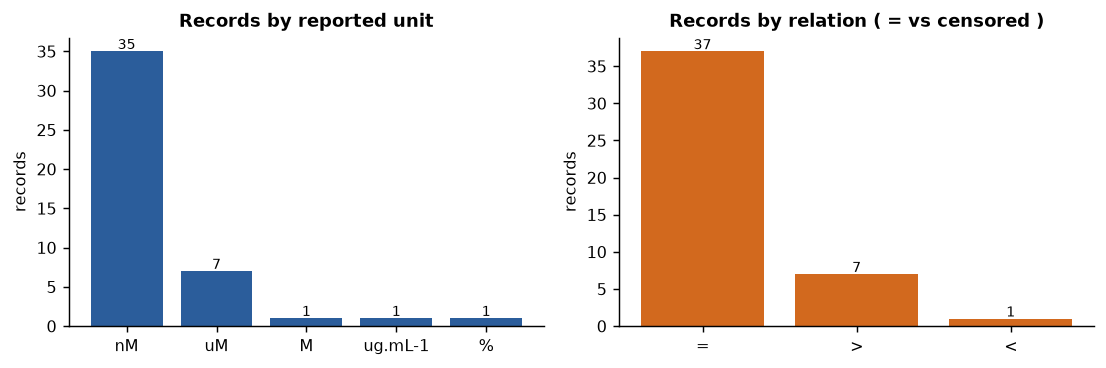

In [7]:
# How many records arrived in each unit and under each relation?
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.6, 2.9))
uc = raw.standard_units.value_counts()
ax1.bar(uc.index.astype(str), uc.values, color="#2b5d9b")
ax1.set_title("Records by reported unit"); ax1.set_ylabel("records")
for i, v in enumerate(uc.values): ax1.text(i, v+0.3, str(v), ha="center", fontsize=8)
rc = raw.standard_relation.value_counts()
ax2.bar(rc.index.astype(str), rc.values, color="#d2691e")
ax2.set_title("Records by relation ( = vs censored )"); ax2.set_ylabel("records")
for i, v in enumerate(rc.values): ax2.text(i, v+0.3, str(v), ha="center", fontsize=8)
fig.tight_layout()
print("units:", uc.to_dict())
print("relations:", rc.to_dict())

<p class="caption"><b>Figure 3.</b> Left: the export mixes nM, µM, M and the two non-standard units µg/mL and % — a single modelling value could not be read off this column without conversion. Right: most relations are "=", but a handful are "&gt;" or "&lt;" — the censored measurements of §4. The printed dictionaries give the exact counts the conversion must handle. Note how a naïve "just take <code>standard_value</code>" would silently compare a number in µM with a number in nM, a 1000-fold error.</p>

In [8]:
# Convert every value to nM; percent is unconvertible; ug/mL needs the molecular weight.
mols_raw = [Chem.MolFromSmiles(s) for s in raw.smiles]
def to_nM(val, unit, mol):
    if val is None or (isinstance(val, float) and np.isnan(val)): return np.nan
    if unit == "nM":  return float(val)
    if unit == "uM":  return float(val) * 1e3
    if unit == "M":   return float(val) * 1e9
    if unit == "ug.mL-1":                        # mg/L / (g/mol) = mmol/L; *1e6 -> nM
        return np.nan if mol is None else float(val) / Descriptors.MolWt(mol) * 1e6
    return np.nan                                # '%', unknown units: cannot be a concentration
raw["ic50_nM"] = [to_nM(v, u, m) for v, u, m in zip(raw.standard_value, raw.standard_units, mols_raw)]
ib = raw.loc[raw.standard_units == "ug.mL-1"].iloc[0]
print(f"ibuprofen 2.5 ug/mL  ->  {ib.ic50_nM:,.0f} nM  (= {ib.ic50_nM/1e3:.1f} uM), using MW "
      f"{Descriptors.MolWt(Chem.MolFromSmiles(ib.smiles)):.1f}")
print("records with no convertible concentration (dropped next):",
      int(raw.ic50_nM.isna().sum()), "->", raw.loc[raw.ic50_nM.isna(), 'name'].tolist())

ibuprofen 2.5 ug/mL  ->  12,119 nM  (= 12.1 uM), using MW 206.3
records with no convertible concentration (dropped next): 2 -> ['paracetamol (no value)', 'benzoic acid (% only)']


The µg/mL row converts only because we had the structure: 2.5 µg/mL of ibuprofen (molecular weight ≈ 206 g/mol) is about 12,000 nM, i.e. ~12 µM — a weak potency that would have looked like a tiny number next to the nanomolar inhibitors if left in its original unit. The percent-inhibition row and the missing-value row produce no convertible concentration and are flagged for removal. We drop them now and record the loss.

In [9]:
# Drop records with no usable concentration (missing value, or percent inhibition).
before = len(raw)
dropped_noconc = raw[raw.ic50_nM.isna()].copy()
work = raw[raw.ic50_nM.notna()].copy()
work["pIC50"] = 9 - np.log10(work.ic50_nM)      # valid for '=', and a *bound* for censored rows
PIPE.append(("usable concentration", len(work), f"-{before-len(work)} missing/percent"))
print(f"dropped {before - len(work)} records with no usable concentration; {len(work)} remain")
print(f"pIC50 now spans {work.pIC50.min():.2f} to {work.pIC50.max():.2f}")
work[["record_id","name","standard_relation","ic50_nM","pIC50"]].head(5)

dropped 2 records with no usable concentration; 43 remain
pIC50 now spans 3.92 to 9.00


,record_id,name,standard_relation,ic50_nM,pIC50
0,R000,gefitinib,=,8.836,8.053744
1,R001,gefitinib,=,12.230,7.912574
2,R002,gefitinib,=,14.010,7.853562
3,R003,gefitinib,=,7.683,8.114469
4,R004,gefitinib,=,14.330,7.843754


<p class="caption"><b>Figure 4.</b> After harmonisation every surviving record carries an <code>ic50_nM</code> and a <code>pIC50</code> on one scale. The two unusable rows are gone and counted. One subtlety is already baked in: the <code>pIC50</code> computed for a censored row (relation "&gt;" or "&lt;") is not a point value but a <em>bound</em>, and §4 decides what to do with it. The printed span confirms the values are in a sane range (roughly 4–9), a cheap sanity check that no unit slipped through.</p>

### 3.1 Worked example by hand: unit harmonisation, pIC50 and replicate aggregation

To be sure the transform is understood and not merely trusted, trace it on paper for three replicate measurements of one compound, reported three different ways, and then aggregate them as §5 will. The point of doing it by hand is that pIC50 is where unit mistakes hide, and a factor-of-1000 slip is invisible once it is inside a log.

| measurement | as reported | to nM | relation | pIC50 = 9 − log₁₀(nM) |
|---|---|---|---|---|
| a | 50 nM | 50 | = | 9 − log₁₀(50) = 9 − 1.699 = **7.30** |
| b | 0.12 µM | 120 | = | 9 − log₁₀(120) = 9 − 2.079 = **6.92** |
| c | "> 10000 nM" | 10000 | &gt; | 9 − log₁₀(10000) = 5.00 → **pIC50 &lt; 5.00 (a bound)** |

Measurement **c** is censored: the true potency is only known to be *weaker than* pIC50 5.0, so it is not a point value and is excluded from a point aggregate. Aggregating the two usable points by their **median** (the robust choice of §5) gives median(7.30, 6.92) = **7.11**. The next cell confirms all of this in code.

In [10]:
# Confirm the hand trace: three replicates -> nM -> pIC50 -> median of the uncensored points.
demo = pd.DataFrame({"reported":["50 nM","0.12 uM",">10000 nM"],
                     "nM":[50.0, 0.12*1e3, 10000.0], "relation":["=","=",">"]})
demo["pIC50"] = 9 - np.log10(demo.nM)
usable = demo[demo.relation == "="]
print(demo.to_string(index=False))
print(f"\nmedian pIC50 of the two uncensored points = {usable.pIC50.median():.2f}  (hand value 7.11)")
print(f"censored point is a bound: pIC50 {'<' if demo.relation.iloc[2]=='>' else '>'} {demo.pIC50.iloc[2]:.2f}")

 reported      nM relation    pIC50
    50 nM    50.0        = 7.301030
  0.12 uM   120.0        = 6.920819
>10000 nM 10000.0        > 5.000000

median pIC50 of the two uncensored points = 7.11  (hand value 7.11)
censored point is a bound: pIC50 < 5.00


The code reproduces the by-hand numbers exactly (7.30, 6.92 and the 5.00 bound; median 7.11), which is the reassurance a sanity check is meant to give: if the code and the arithmetic ever disagree, there is a bug in the conversion, not in the chemistry. This is the rhythm the whole unit follows — a defensible chemical rule, then the few lines that make it operational, then a check.

## 4. Censored measurements: "&gt;" and "&lt;"

A censored value is one the experiment could only bound, not pin down. Every assay has a <strong>dynamic range</strong>: a lowest and highest concentration it can test. If a compound is still not half-inhibiting the target at the highest concentration tested, the result is reported as "IC50 &gt; (that concentration)" — the compound is weak, but exactly how weak is unknown. The mirror case, "IC50 &lt; (lowest concentration)", means the compound was already more than half-inhibiting at the lowest dose: very potent, but the exact value is below the floor. Statisticians call this left- and right-censoring; it is the same phenomenon as a sensor that saturates.

<div class="box bridge"><h4>Chemistry box — detection limit and dynamic range</h4>
<p>Think of the assay as a measuring cup with a lowest and a highest mark. A "&gt;" result is "the liquid is above the top mark — at least this much, we cannot say how much more"; a "&lt;" result is "below the bottom mark". The numeric value attached to a censored record is the <em>mark</em> (the limit of the assay), not the compound's true potency. Treating that limit as if it were the measured value is a common and damaging error: it invents precision the experiment never had.</p></div>

There is no single correct policy, and the honest ones are: (i) <strong>drop</strong> censored records — simplest, and standard when building a regression set of precise values, at the cost of discarding real information that the compound is weak or strong; (ii) <strong>keep them as bounds</strong> for a model that can use inequalities (e.g. censored-aware or classification models); or (iii) <strong>treat the limit as the value</strong> — convenient but biased, and only defensible for coarse classification where "weaker than 10 µM" safely means "inactive". The right choice depends on the downstream task, which is why censoring is a <em>curation decision</em>, not a mechanical step.<sup class="c"><a href="#r4">[4]</a></sup> We quantify how many records each policy keeps.

censored records: 8  ( '>' : 7,  '<' : 1 )  of 43 total


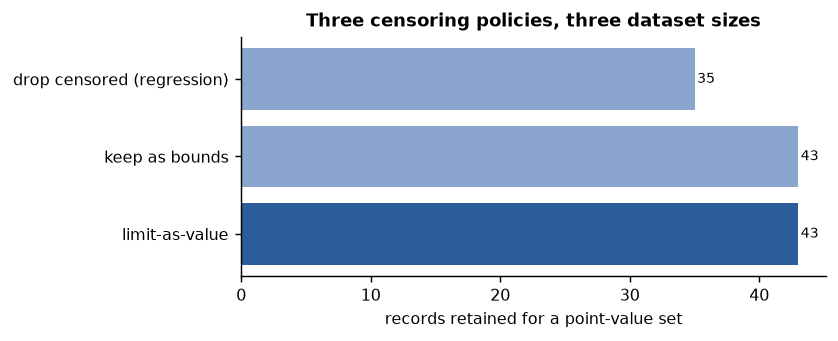

In [11]:
# How many censored records, and what three policies would keep for a regression set?
cens = work[work.standard_relation != "="]
n_gt = int((work.standard_relation == ">").sum()); n_lt = int((work.standard_relation == "<").sum())
policy = {"drop censored (regression)": int((work.standard_relation == "=").sum()),
          "keep as bounds": len(work),
          "limit-as-value": len(work)}
print(f"censored records: {len(cens)}  ( '>' : {n_gt},  '<' : {n_lt} )  of {len(work)} total")
fig, ax = plt.subplots(figsize=(6.6, 2.7))
ax.barh(list(policy)[::-1], list(policy.values())[::-1], color=["#8aa6cf","#8aa6cf","#2b5d9b"][::-1])
for i, v in enumerate(list(policy.values())[::-1]): ax.text(v+0.2, i, str(v), va="center", fontsize=8)
ax.set_xlabel("records retained for a point-value set"); ax.set_title("Three censoring policies, three dataset sizes")
fig.tight_layout()

<p class="caption"><b>Figure 5.</b> The censoring policy alone changes the size of the dataset you hand to a model. Dropping censored records (the conservative choice for a precise-value regression) discards the handful of "&gt;"/"&lt;" rows; keeping them as bounds or substituting the limit retains them. We adopt policy (i) for the regression-style demonstrations that follow — the clean point-value set — but we <em>keep the censored rows aside, not deleted</em>, because they are legitimate information for the classification task of §8 (a "&gt; 10 µM" compound is confidently inactive). Deciding this now, in the open, is the difference between curation and quiet data loss.</p>

In [12]:
# Keep an explicit point-value set (relation '='); set the censored rows aside, don't delete them.
censored_aside = work[work.standard_relation != "="].copy()
pts = work[work.standard_relation == "="].copy()
PIPE.append(("'=' point values", len(pts), f"{len(censored_aside)} censored set aside (kept for classification)"))
print(f"point-value set: {len(pts)} rows; censored set aside: {len(censored_aside)} rows")
print("compounds represented in the point-value set:", pts.compound_id.nunique())

point-value set: 35 rows; censored set aside: 8 rows
compounds represented in the point-value set: 12


## 5. Deduplication and replicate aggregation

The export has many rows per compound — different assays, different laboratories, the same molecule drawn with a salt attached, even an exact duplicate row. Before modelling, each unique <em>structure</em> must become one record, and the several measurements of it must be combined into one value. Two questions have to be answered: how do we decide two rows are "the same molecule", and how do we combine their numbers.

<div class="box bridge"><h4>Chemistry box — what counts as "the same molecule"</h4>
<p>Two records are the same compound if they have the same molecular structure after cleaning. The reliable key is not the raw SMILES string (the same molecule has many valid SMILES) but a <strong>canonical identifier</strong> computed from the structure. We use the <strong>InChIKey</strong><sup class="c"><a href="#r10">[10]</a></sup>: a fixed-length hash of the standard InChI identifier whose first block encodes the molecular skeleton (atoms and bonds). It is the chemistry equivalent of hashing a record to a canonical form before a group-by — the job canonical SMILES<sup class="c"><a href="#r9">[9]</a></sup> also does — and we compute both the key and the salt-stripping with RDKit.<sup class="c"><a href="#r8">[8]</a></sup> We first strip salts to the parent structure (§6 explains why) so that "drug" and "drug·HCl" map to the same key.</p></div>

For combining the numbers, the choice is driven by what we know about the noise. Large analyses of public data show that the same compound–target pair, measured in different laboratories, scatters by roughly half a log unit or more: Kalliokoski et al. found a standard deviation near 0.7 log units for heterogeneous ChEMBL IC50 data,<sup class="c"><a href="#r2">[2]</a></sup> and Kramer et al. reported about 0.5 log units even for the cleaner Ki data.<sup class="c"><a href="#r11">[11]</a></sup> A recent re-analysis warns specifically against pooling IC50 or Ki values from different assays without accounting for this noise.<sup class="c"><a href="#r21">[21]</a></sup> The practical consequences: (a) aggregate on the log (pIC50) scale, where the noise is roughly symmetric; (b) prefer the <strong>median</strong> over the mean, since it resists a single wild outlier; and (c) if the replicates of one compound disagree by far more than ~1 log unit, that compound is a candidate for manual review, not blind averaging.

In [13]:
# Standardise each structure to its salt-free parent and compute a canonical InChIKey skeleton key.
lfc = rdMolStandardize.LargestFragmentChooser()
def structure_key(smi):
    m = Chem.MolFromSmiles(smi)
    if m is None: return None, None, 0, False
    parent = lfc.choose(m)                              # keep the largest fragment (strip salts/counter-ions)
    frags = Chem.GetMolFrags(m, asMols=True)
    n_org = sum(1 for f in frags if any(a.GetSymbol() == "C" for a in f.GetAtoms()))  # organic components
    has_c = any(a.GetSymbol() == "C" for a in parent.GetAtoms())                      # carbon in the parent?
    key = inchi.MolToInchiKey(parent).split("-")[0]     # first block = connectivity skeleton
    return parent, key, n_org, has_c
keys = [structure_key(s) for s in pts.smiles]
pts["parent"] = [k[0] for k in keys]; pts["skeleton"] = [k[1] for k in keys]
pts["n_org"] = [k[2] for k in keys]; pts["has_carbon"] = [k[3] for k in keys]
print("point-value rows:", len(pts), "| distinct skeleton keys:", pts.skeleton.nunique())
print("example: gefitinib and its HCl salt share a key ->",
      pts.loc[pts.name.str.startswith('gefitinib'), 'skeleton'].nunique() == 1)

point-value rows: 35 | distinct skeleton keys: 12
example: gefitinib and its HCl salt share a key -> True


The salt-stripping step has already done real work: the free base of gefitinib and its hydrochloride salt collapse to one skeleton key, as the printout confirms, and the exact-duplicate erlotinib row joins the other erlotinib measurements. The number of distinct skeleton keys is now the number of real compounds in the point-value set. Before we aggregate, let us look at the replicate scatter, because it is the single most important thing to understand about bioactivity data.

pooled within-compound SD = 0.31 log units (real public data: ~0.5-0.7; Kalliokoski 2013, Kramer 2012)


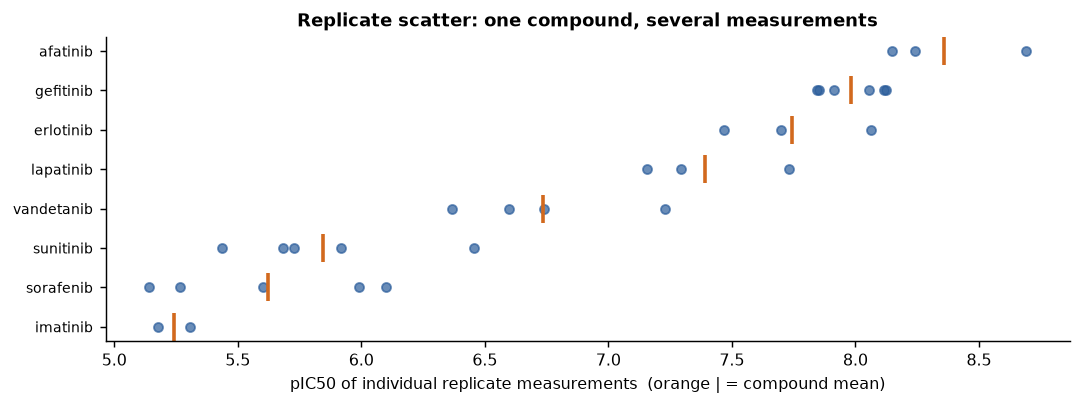

In [14]:
# Replicate scatter per compound on the pIC50 scale, with the ~0.5-0.7 log experimental-noise band.
grp = pts.groupby("skeleton")
spread = grp.pIC50.agg(["count","mean","std","min","max"]).dropna(subset=["std"]).sort_values("mean")
names = [pts.loc[pts.skeleton == k, "name"].iloc[0].split(" (")[0] for k in spread.index]
fig, ax = plt.subplots(figsize=(8.4, 3.2))
for i, k in enumerate(spread.index):
    vals = pts.loc[pts.skeleton == k, "pIC50"].values
    ax.plot(vals, [i]*len(vals), "o", color="#2b5d9b", alpha=0.7, ms=5)
    ax.plot(spread.loc[k, "mean"], i, "|", color="#d2691e", ms=16, mew=2)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8)
ax.set_xlabel("pIC50 of individual replicate measurements  (orange | = compound mean)")
ax.set_title("Replicate scatter: one compound, several measurements")
pooled = np.sqrt(np.nanmean(spread["std"].values**2))
print(f"pooled within-compound SD = {pooled:.2f} log units "
      f"(real public data: ~0.5-0.7; Kalliokoski 2013, Kramer 2012)")
fig.tight_layout()

<p class="caption"><b>Figure 6.</b> Each row is one compound; the blue dots are its individual replicate measurements and the orange tick is their mean. The measurements of a single compound scatter visibly — here with a pooled within-compound standard deviation of about the value printed. Our synthetic noise (0.35 log units) is deliberately <em>smaller</em> than the real-world figure of roughly 0.5–0.7 log units reported for public IC50 and Ki data;<sup class="c"><a href="#r2">[2]</a></sup><sup class="c"><a href="#r11">[11]</a></sup> real data is messier than this. The practical lesson is sobering: if two compounds differ in reported pIC50 by less than about half a log unit, that difference may be pure measurement noise. This sets a hard ceiling on how good any model can honestly be — no model can predict potency more precisely than the data was measured.<sup class="c"><a href="#r19">[19]</a></sup></p>

In [15]:
# Aggregate to one record per compound: median pIC50 on the log scale (robust to outliers).
agg = (pts.groupby("skeleton")
          .agg(name=("name", lambda s: s.iloc[0].split(" (")[0]),
               compound_id=("compound_id", "first"),
               smiles=("smiles", "first"),
               n_meas=("pIC50", "size"),
               pIC50=("pIC50", "median"),
               pIC50_range=("pIC50", lambda s: s.max() - s.min()))
          .reset_index())
PIPE.append(("unique compounds", len(agg), f"aggregated {len(pts)} rows -> median pIC50"))
print(f"{len(pts)} point-value rows -> {len(agg)} unique compounds (median pIC50 per compound)")
print(f"largest within-compound range: {agg.pIC50_range.max():.2f} log units "
      f"({agg.loc[agg.pIC50_range.idxmax(), 'name']})")
agg.sort_values("pIC50", ascending=False)[["name","n_meas","pIC50","pIC50_range"]].head(6)

35 point-value rows -> 12 unique compounds (median pIC50 per compound)
largest within-compound range: 1.02 log units (sunitinib)


,name,n_meas,pIC50,pIC50_range
7,afatinib,3,8.239804,0.542701
9,gefitinib,6,7.983159,0.281185
0,erlotinib,3,7.698970,0.597778
1,lapatinib,3,7.292600,0.575133
11,vandetanib,4,6.668344,0.862094
8,sunitinib,5,5.726536,1.016372


<p class="caption"><b>Figure 7.</b> The aggregated table: one row per compound, with <code>n_meas</code> recording how many measurements were combined and <code>pIC50_range</code> how far they spread. Recording these provenance columns is itself curation — a reviewer (or your future self) can see at a glance which values rest on a single measurement and which compounds had discordant replicates worth re-checking. We have gone from a pile of measurement rows to a compound table, deduplicated by canonical structure and aggregated by median. What remains is to remove records that are not drug-like molecules at all.</p>

## 6. Salts, mixtures and inorganics

Three kinds of record are structurally unfit for a standard ligand-based model and must be removed or repaired on principled grounds — the same cleanup the ChEMBL structure-curation pipeline performs.<sup class="c"><a href="#r7">[7]</a></sup>

<div class="box bridge"><h4>Chemistry box — salts, mixtures and inorganics</h4>
<p>A <strong>salt</strong> is a drug paired with a small <em>counter-ion</em> (for example chloride, Cl⁻, or sodium, Na⁺) to make it easier to crystallise and formulate; the counter-ion is not part of the active molecule, so it is stripped to leave the <strong>parent</strong> structure (we already did this to build the dedup key). A <strong>mixture</strong> is a record whose structure is two or more distinct compounds — after salt-stripping, more than one sizeable organic fragment remains — so it is ambiguous which component the potency belongs to; such records are dropped. An <strong>inorganic</strong> or <strong>organometallic</strong> compound is one built around metals or containing no carbon at all (cisplatin, a platinum drug, is the classic case); the descriptors and fingerprints of ligand-based cheminformatics are designed for organic molecules and are not meaningful for these, so they are excluded and the exclusion is stated. None of this means the dropped records are "bad science" — it means they are outside the chemical domain the model is built for.</p></div>

We already computed, per record, the number of fragments and whether the parent contains carbon. Applying the rules to the aggregated table lets us remove mixtures and inorganics and count each drop. (The salt was already handled, silently merging into its parent during dedup — the correct, non-destructive outcome.)

In [16]:
# Flag mixtures (>1 fragment) and inorganics (parent has no carbon) on the aggregated compounds.
info = {k: structure_key(s) for k, s in zip(agg.skeleton, agg.smiles)}
agg["n_org"] = [info[k][2] for k in agg.skeleton]
agg["has_carbon"] = [info[k][3] for k in agg.skeleton]
is_inorganic = ~agg.has_carbon                          # no carbon in the parent => inorganic/organometallic
is_mixture = (agg.n_org > 1) & agg.has_carbon           # >1 organic component => a true mixture
dropped_struct = agg[is_mixture | is_inorganic].copy()
clean = agg[~(is_mixture | is_inorganic)].copy()
PIPE.append(("organic, single-component", len(clean),
             f"-{int(is_mixture.sum())} mixture, -{int(is_inorganic.sum())} inorganic"))
print(f"dropped {int(is_mixture.sum())} mixture(s) and {int(is_inorganic.sum())} inorganic(s); {len(clean)} compounds remain")
print("dropped:", dropped_struct[["name","n_org","has_carbon"]].to_dict("records"))

dropped 1 mixture(s) and 1 inorganic(s); 10 compounds remain
dropped: [{'name': 'aspirin + salicylate', 'n_org': 2, 'has_carbon': True}, {'name': 'cisplatin', 'n_org': 0, 'has_carbon': False}]


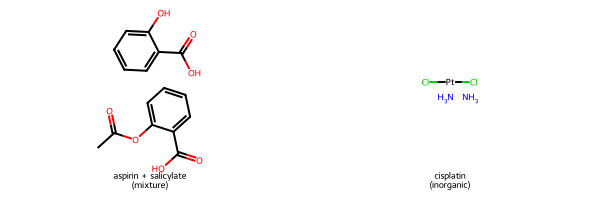

In [17]:
# Draw the records removed as structurally unfit, so the decision is visible and auditable.
show = dropped_struct.copy()
mols = [Chem.MolFromSmiles(s) for s in show.smiles]
legs = [f"{n}\n({'inorganic' if not hc else 'mixture'})" for n, hc in zip(show.name, show.has_carbon)]
Draw.MolsToGridImage(mols, molsPerRow=2, subImgSize=(300, 200), legends=legs)

<p class="caption"><b>Figure 8.</b> The structurally unfit records, drawn so the curation decision can be audited rather than taken on trust. The aspirin + salicylate record is a two-component <em>mixture</em> — the potency cannot be assigned to one molecule — and cisplatin is an <em>inorganic</em>/organometallic built around platinum with no organic scaffold for a fingerprint to describe. Showing the dropped structures is a small habit with a large payoff: it is how you catch a rule that is too aggressive (throwing away legitimate compounds) or too lax (letting junk through), which is the recurring warning of the curation literature.<sup class="c"><a href="#r1">[1]</a></sup></p>

## 7. Assay heterogeneity: what may be merged

Even after structural cleanup, a subtle hazard remains: the surviving measurements came from several assays and even two measurement <em>types</em> (IC50 and Ki). Pooling numbers that were produced by different experiments is only valid if those experiments measure comparable things. IC50 and Ki are related but assay-dependent; EC50 from a functional assay is a different quantity again; and two "IC50" assays can differ in their readout and conditions enough that their values are not directly comparable.<sup class="c"><a href="#r21">[21]</a></sup> The curation decision is therefore: merge only within a coherent measurement type and a comparable assay family, and record what was merged.

assays: {'ASSAY-A1': 8, 'ASSAY-A2': 6, 'ASSAY-A3': 12, 'ASSAY-A4': 9} | types: {'IC50': 30, 'Ki': 5}


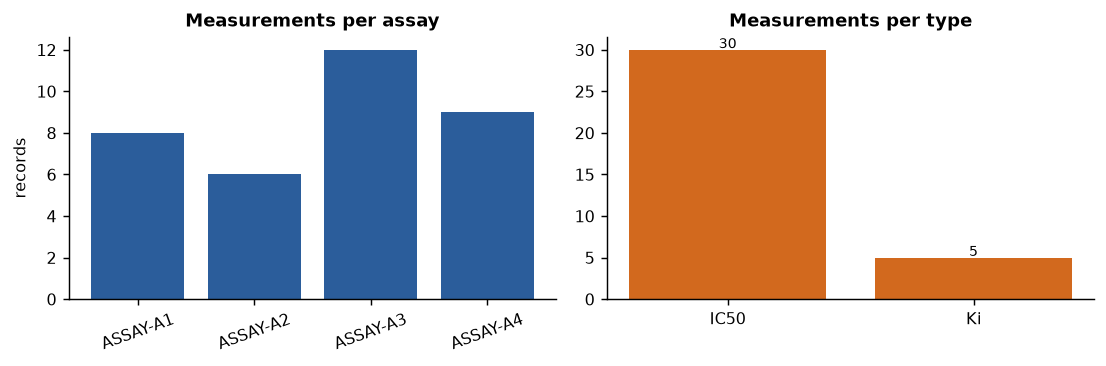

In [18]:
# Where did the surviving point-value measurements come from, by assay and by type?
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.6, 2.9))
ac = pts.assay_id.value_counts().sort_index()
ax1.bar(ac.index.astype(str), ac.values, color="#2b5d9b"); ax1.set_title("Measurements per assay")
ax1.set_ylabel("records"); ax1.tick_params(axis="x", labelrotation=20)
tc = pts.standard_type.value_counts()
ax2.bar(tc.index.astype(str), tc.values, color="#d2691e"); ax2.set_title("Measurements per type")
for i, v in enumerate(tc.values): ax2.text(i, v+0.2, str(v), ha="center", fontsize=8)
fig.tight_layout()
print("assays:", ac.to_dict(), "| types:", tc.to_dict())

<p class="caption"><b>Figure 9.</b> The point-value measurements are spread over four assays and include both IC50 and a minority of Ki rows. In a strict curation you would separate these — modelling IC50 and Ki as distinct endpoints, or converting between them only with an explicit, justified assumption — and you would check that the assays share a comparable protocol before merging. Our teaching sample treats them as one endpoint for simplicity, and <em>says so</em>; the honest move in a real project is to report the assay and type mix (as this figure does) so a reader can judge whether the pooling was defensible.<sup class="c"><a href="#r16">[16]</a></sup> Under-reported assay heterogeneity is one of the quiet reasons published models fail to reproduce.<sup class="c"><a href="#r3">[3]</a></sup>

## 8. Thresholding for classification

Many cheminformatics tasks are framed as classification — "active" versus "inactive" — rather than regression on a continuous pIC50. That requires a <strong>threshold</strong>, and the threshold is a modelling choice with chemical and statistical consequences, not a neutral default.

<div class="box bridge"><h4>Chemistry box — the active/inactive cut and the grey zone</h4>
<p>A common convention calls a compound <strong>active</strong> if its potency beats some cutoff, e.g. IC50 ≤ 1 µM, i.e. pIC50 ≥ 6. Compounds just on either side of the line are barely distinguishable: given that measurements scatter by ~0.5 log units (§5), a compound at pIC50 5.9 and one at 6.1 may really be equipotent. This band around the threshold is the <strong>grey zone</strong>, and labels assigned inside it are the noisiest in the dataset. A stricter cutoff makes "active" mean more but yields fewer positives and a more imbalanced dataset; a looser cutoff does the opposite. There is no universally right value — only a value you choose deliberately and report.</p></div>

The next cell sweeps the threshold and shows how the fraction of actives — and therefore the class balance a classifier must cope with — slides as the cutoff moves.

active fraction at pIC50>=6.0: 0.5 | at >=7.0: 0.4


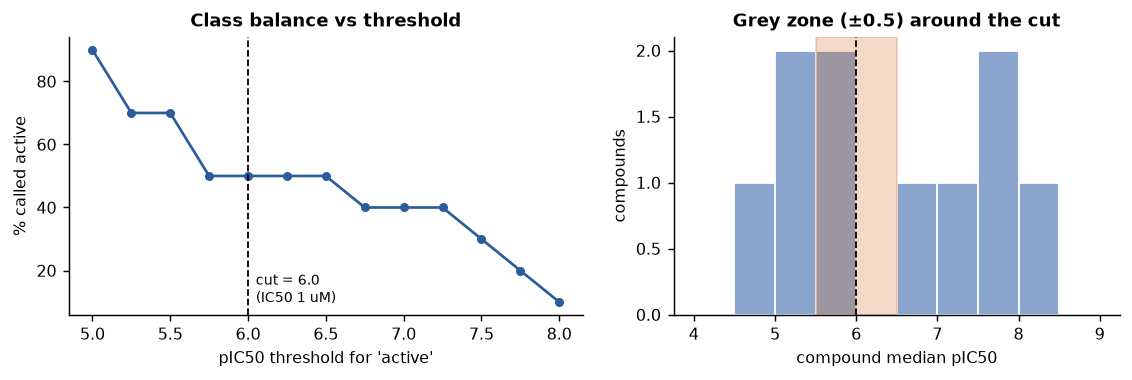

In [19]:
# How the active fraction depends on the chosen pIC50 threshold, on the curated compound set.
cls = clean[["name","pIC50"]].copy()
thr_grid = np.arange(5.0, 8.01, 0.25)
frac = [float((cls.pIC50 >= t).mean()) for t in thr_grid]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.8, 3.0), gridspec_kw={"width_ratios":[1.15,1]})
ax1.plot(thr_grid, 100*np.array(frac), "-o", color="#2b5d9b", ms=4)
ax1.axvline(6.0, color="k", ls="--", lw=1); ax1.text(6.05, 10, "cut = 6.0\n(IC50 1 uM)", fontsize=8)
ax1.set_xlabel("pIC50 threshold for 'active'"); ax1.set_ylabel("% called active"); ax1.set_title("Class balance vs threshold")
ax2.hist(cls.pIC50, bins=np.arange(4,9.1,0.5), color="#8aa6cf", ec="white")
ax2.axvspan(5.5, 6.5, color="#d2691e", alpha=0.25); ax2.axvline(6.0, color="k", ls="--", lw=1)
ax2.set_xlabel("compound median pIC50"); ax2.set_title("Grey zone (±0.5) around the cut"); ax2.set_ylabel("compounds")
fig.tight_layout()
print("active fraction at pIC50>=6.0:", round(float((cls.pIC50>=6).mean()),2),
      "| at >=7.0:", round(float((cls.pIC50>=7).mean()),2))

<p class="caption"><b>Figure 10.</b> Left: the share of compounds labelled "active" falls steadily as the threshold rises — the same dataset is majority-active at a loose cut and minority-active at a strict one, and the printout gives the exact fractions at pIC50 ≥ 6 and ≥ 7. Right: the shaded band is the grey zone (±0.5 log units) around a pIC50 = 6 cut; the compounds inside it are the ones whose active/inactive label is least trustworthy. A classifier's reported accuracy, and especially its apparent precision, can be moved substantially just by sliding this one number — which is why the threshold must be chosen before you look at model performance, and reported alongside it.</p>

## 9. One curation choice, measured: deduplicate before or after splitting

Everything so far has been about producing a defensible table. This section shows, concretely, that a single curation choice changes a downstream metric — the point the whole unit has been building toward. The choice is the most consequential one in molecular ML evaluation: <strong>do you deduplicate replicate structures before or after you split the data into train and test?</strong>

If you split the <em>raw per-measurement rows</em> at random, replicates of the same molecule land on both sides of the split. A model is then tested on structures it has effectively already seen — the textbook definition of <strong>data leakage</strong> — and its measured error collapses to near the experimental noise, flattering it enormously.<sup class="c"><a href="#r20">[20]</a></sup> If instead you aggregate to one record per unique structure <em>first</em> and only then split, the test molecules are genuinely unseen and the error reflects real predictive difficulty. We demonstrate with the simplest possible model — a 1-nearest-neighbour regressor on Morgan fingerprints, evaluated leave-one-out — so the effect is clearly the data, not the model. (Honest validation protocols — scaffold splits, applicability domain — are Unit 14; here we isolate the single curation effect.)

In [20]:
# Featurise once: Morgan fingerprints (ECFP-like) for every point-value row and every unique compound.
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
def fps(smiles_list):
    X = np.zeros((len(smiles_list), 1024), dtype=bool)   # boolean bits -> Jaccard needs no conversion
    for i, s in enumerate(smiles_list):
        m = lfc.choose(Chem.MolFromSmiles(s))          # parent, so salt rows match their compound
        a = np.zeros((1024,), dtype=np.int8); ConvertToNumpyArray(gen.GetFingerprint(m), a); X[i] = a.astype(bool)
    return X
X_rows, y_rows = fps(pts.smiles.tolist()), pts.pIC50.values            # leaky: replicates present
X_cpd,  y_cpd  = fps(clean.smiles.tolist()), clean.pIC50.values       # deduplicated compounds
print(f"row-level set: {len(y_rows)} measurements; compound-level set: {len(y_cpd)} unique compounds")

row-level set: 35 measurements; compound-level set: 10 unique compounds


In [21]:
# Leave-one-out 1-NN RMSE under the two curation choices (same model, same features).
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import LeaveOneOut
def loo_rmse(X, y):
    pred = np.empty_like(y, dtype=float)
    for tr, te in LeaveOneOut().split(X):
        knn = KNeighborsRegressor(n_neighbors=1, metric="jaccard").fit(X[tr], y[tr])
        pred[te] = knn.predict(X[te])
    return float(np.sqrt(np.mean((pred - y)**2)))
rmse_leaky = loo_rmse(X_rows, y_rows)       # duplicates split across train/test
rmse_clean = loo_rmse(X_cpd,  y_cpd)        # deduplicated first
print(f"RMSE, split BEFORE dedup (leaky)   = {rmse_leaky:.2f} log units  <- flattering")
print(f"RMSE, dedup BEFORE split (honest)  = {rmse_clean:.2f} log units  <- real difficulty")
print(f"the curation choice changes the reported error by a factor of {rmse_clean/max(rmse_leaky,1e-6):.1f}")

RMSE, split BEFORE dedup (leaky)   = 0.55 log units  <- flattering
RMSE, dedup BEFORE split (honest)  = 1.17 log units  <- real difficulty
the curation choice changes the reported error by a factor of 2.1


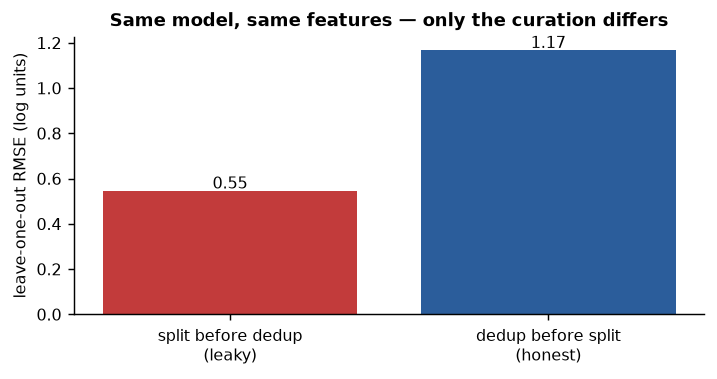

In [22]:
# Visualise the two reported errors side by side.
fig, ax = plt.subplots(figsize=(5.6, 3.0))
bars = ax.bar(["split before dedup\n(leaky)", "dedup before split\n(honest)"],
              [rmse_leaky, rmse_clean], color=["#c23b3b", "#2b5d9b"])
for b, v in zip(bars, [rmse_leaky, rmse_clean]): ax.text(b.get_x()+b.get_width()/2, v+0.01, f"{v:.2f}", ha="center", fontsize=9)
ax.set_ylabel("leave-one-out RMSE (log units)"); ax.set_title("Same model, same features — only the curation differs")
fig.tight_layout()

<p class="caption"><b>Figure 11.</b> The identical model and features give very different "performance" depending only on whether duplicate structures were removed before the split. Splitting the raw measurement rows lets replicates leak across train and test, so a 1-NN model nearly reproduces each held-out value and the RMSE looks small; deduplicating first removes the leak and the RMSE jumps to reflect the genuine difficulty of predicting an unseen compound. The exact numbers are from a deliberately tiny sample and are illustrative, but the <em>direction and size</em> of the effect are the robust, well-documented lesson:<sup class="c"><a href="#r20">[20]</a></sup><sup class="c"><a href="#r22">[22]</a></sup> a curation decision made upstream silently sets the honesty of every metric reported downstream. This is precisely the mechanism behind many over-optimistic published QSAR results.<sup class="c"><a href="#r19">[19]</a></sup>

## 10. The audited pipeline, the data sheet and provenance

Curation is only trustworthy if it is reproducible and documented. A reviewer must be able to see how many records entered, how many left at each step and why, and what the final set contains — the data-sheet discipline that FAIR data principles<sup class="c"><a href="#r17">[17]</a></sup> and modern benchmarking guidance<sup class="c"><a href="#r18">[18]</a></sup> ask for; standardised, consistently curated ChEMBL benchmark sets exist precisely so that models can be compared on the same clean data.<sup class="c"><a href="#r23">[23]</a></sup> We first draw the funnel from the running log we have kept, then print a one-page data sheet.

stages: [('raw export', 45), ('usable concentration', 43), ("'=' point values", 35), ('unique compounds', 12), ('organic, single-component', 10)]


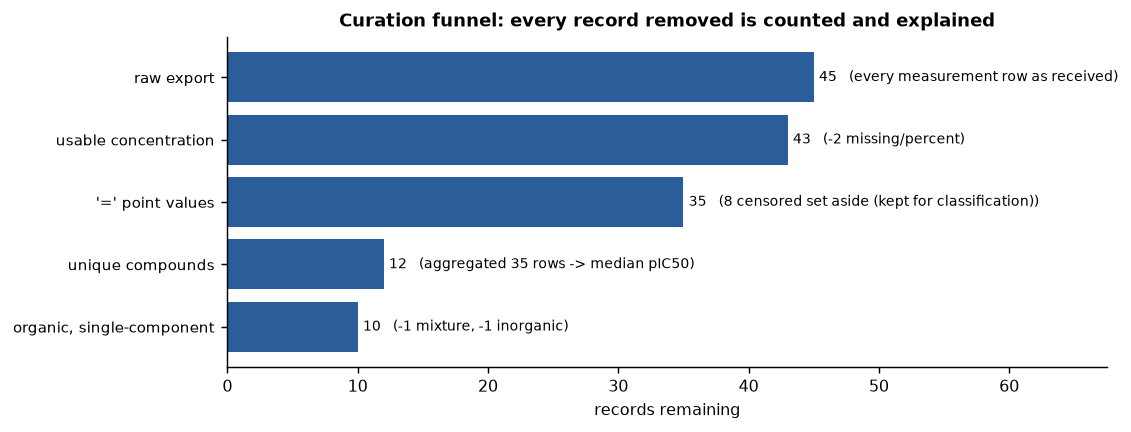

In [23]:
# The curation funnel: record count after each stage, drawn from the PIPE log kept throughout.
labels = [p[0] for p in PIPE]; counts = [p[1] for p in PIPE]; notes = [p[2] for p in PIPE]
fig, ax = plt.subplots(figsize=(8.8, 3.4))
ypos = np.arange(len(labels))[::-1]
ax.barh(ypos, counts, color="#2b5d9b")
for y, c, n in zip(ypos, counts, notes):
    ax.text(c+0.4, y, f"{c}   ({n})", va="center", fontsize=7.6)
ax.set_yticks(ypos); ax.set_yticklabels(labels, fontsize=8.5)
ax.set_xlim(0, max(counts)*1.5); ax.set_xlabel("records remaining")
ax.set_title("Curation funnel: every record removed is counted and explained")
fig.tight_layout()
print("stages:", [(l, c) for l, c in zip(labels, counts)])

<p class="caption"><b>Figure 12.</b> The funnel reads top to bottom: the raw export, then the set with a usable concentration (percent and missing dropped), the "=" point-value set (censored rows set aside), the unique-compound set after median aggregation, and finally the organic single-component set after mixtures and the inorganic were removed. Each bar is annotated with the reason for the change, so the drop from raw to final is fully accounted for — no record vanishes unexplained. This single figure is, in practice, the most important deliverable of a curation step: it is the evidence that the dataset is what you claim it is.</p>

  target                      : protein kinase (synthetic EGFR-like teaching sample)
  endpoint                    : pIC50 (median of IC50 replicates, '=' only)
  raw_records                 : 45
  final_compounds             : 10
  pIC50_min                   : 4.92
  pIC50_median                : 6.2
  pIC50_max                   : 8.24
  active_fraction_cut6        : 0.5
  censored_set_aside          : 8
  typical_experimental_noise  : ~0.5-0.7 log units (literature)
  seed                        : 0


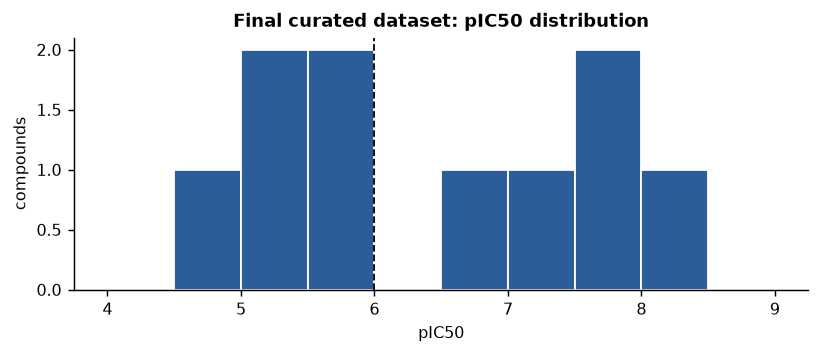

In [24]:
# A one-page data sheet for the curated dataset, plus the final pIC50 distribution.
sheet = {
 "target": "protein kinase (synthetic EGFR-like teaching sample)",
 "endpoint": "pIC50 (median of IC50 replicates, '=' only)",
 "raw_records": PIPE[0][1],
 "final_compounds": len(clean),
 "pIC50_min": round(float(clean.pIC50.min()), 2),
 "pIC50_median": round(float(clean.pIC50.median()), 2),
 "pIC50_max": round(float(clean.pIC50.max()), 2),
 "active_fraction_cut6": round(float((clean.pIC50 >= 6).mean()), 2),
 "censored_set_aside": len(censored_aside),
 "typical_experimental_noise": "~0.5-0.7 log units (literature)",
 "seed": 0,
}
for k, v in sheet.items(): print(f"  {k:28s}: {v}")
fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.hist(clean.pIC50, bins=np.arange(4, 9.1, 0.5), color="#2b5d9b", ec="white")
ax.axvline(6.0, color="k", ls="--", lw=1); ax.set_xlabel("pIC50"); ax.set_ylabel("compounds")
ax.set_title("Final curated dataset: pIC50 distribution")
fig.tight_layout()

<p class="caption"><b>Figure 13.</b> The curated dataset, summarised. The data sheet states the target, endpoint, record counts in and out, the pIC50 range and median, the active fraction at the chosen cut, how many censored rows were kept aside, the typical experimental noise that bounds achievable accuracy, and the random seed that makes the whole notebook reproducible. The histogram shows the final pIC50 spread with the active/inactive cut marked. A real project would additionally freeze this table to a versioned file with a checksum and record the exact database release it came from<sup class="c"><a href="#r5">[5]</a></sup> — data versioning is as important for a model as code versioning is for software.

<div class="box warn"><h4>What this curated set still cannot promise</h4>
<p>Curation removes defects; it does not remove the limits of the underlying data. The aggregated potencies still carry ~0.5 log units of irreducible experimental noise, so no model built on them can be more precise than that.<sup class="c"><a href="#r2">[2]</a></sup> The assay heterogeneity of §7 was simplified away for teaching, not solved. And a clean table says nothing about whether the compounds cover the chemistry you will later apply the model to — the applicability-domain question of Unit 14. Honest curation ends with a clear statement of what the dataset does <em>not</em> support,<sup class="c"><a href="#r19">[19]</a></sup> which is why the data sheet above lists its own caveats.</p></div>

<div class="box bridge"><h4>Bridge — curation is not the only gate</h4>
<p>This unit cleaned the <em>potency</em> column. A complementary question is whether each surviving molecule is a plausible drug at all — its size, lipophilicity (estimated as logP from structure<sup class="c"><a href="#r14">[14]</a></sup>) and polarity. Rule-based filters such as Lipinski's rule of five<sup class="c"><a href="#r27">[27]</a></sup> and composite scores such as QED<sup class="c"><a href="#r26">[26]</a></sup> address that question and are the subject of Unit 9. A curated activity table and a drug-likeness screen are two different cleaning steps applied to the same collection; both belong in a defensible pipeline.</p></div>

## 11. Summary

You should now be able to explain, without notes:

- Why public bioactivity data is noisy and error-prone, and why curation is the step that most determines whether a model learns chemistry or noise.<sup class="c"><a href="#r1">[1]</a></sup>
- How to harmonise mixed units to nM, including the µg/mL case that requires a molecular weight, and why percent inhibition cannot be converted.
- The careful definition pIC50 = 9 − log₁₀(IC50 in nM), its relatives pKi and pChEMBL, and why potencies are modelled on the log scale.
- What censored "&gt;"/"&lt;" values mean physically and the three defensible policies for them.
- How to deduplicate by a canonical structure key (InChIKey skeleton after salt-stripping) and aggregate replicates by the median on the log scale, and why the residual scatter is ~0.5 log units.
- Why salts are stripped, and mixtures and inorganics dropped, for a ligand-based model — and the habit of drawing what you drop.
- How the classification threshold moves the class balance and creates a noisy grey zone.
- That deduplicating before versus after a split changes a reported metric, because duplicates leak across train and test.
- How to document the whole pipeline as a counted funnel and a one-page data sheet, and to state honestly what the dataset cannot support.

## 12. Self-assessment

<details><summary>1. Why is pIC50 = 9 − log₁₀(IC50 in nM), and what is pIC50 for an IC50 of 250 nM?</summary>Because pIC50 = −log₁₀(IC50 in molar) and 1 nM = 10⁻⁹ M, so −log₁₀(value×10⁻⁹) = 9 − log₁₀(value in nM). For 250 nM: 9 − log₁₀(250) = 9 − 2.398 = 6.60.</details>

<details><summary>2. A row reports an IC50 of 5 in units of µM. A colleague reads the value column as nanomolar. By what factor is the potency wrong, and in which direction?</summary>5 µM = 5000 nM. Reading "5" as nM makes the compound look 1000× more potent than it is. Unit harmonisation before anything else exists to prevent exactly this 1000-fold error.</details>

<details><summary>3. What does a measurement of "IC50 &gt; 10000 nM" tell you, and why is it wrong to enter 10000 nM as the compound's potency?</summary>It means the compound did not reach half-inhibition even at the top tested concentration (10 µM): it is weak, but the true IC50 is unknown and larger than 10 µM. Entering 10000 nM as the value invents a precise potency the assay never measured — a biased, censored-ignoring shortcut only acceptable for coarse "inactive" labelling.</details>

<details><summary>4. Why convert a µg/mL value with the molecular weight, but refuse to convert a percent-inhibition value at all?</summary>µg/mL is a mass concentration; dividing by MW (g/mol) converts mass to moles, giving a molar concentration comparable to nM. Percent inhibition is not a concentration — it is the effect size at one fixed dose — so there is no conversion to the IC50 scale and the row must be dropped.</details>

<details><summary>5. Why deduplicate on an InChIKey skeleton rather than on the raw SMILES string?</summary>One molecule has many valid SMILES strings, so grouping by raw SMILES would leave true duplicates unmerged. The InChIKey is computed canonically from the structure, so the same molecule always yields the same key; its first block encodes the connectivity skeleton, merging salt/parent and redrawn duplicates.</details>

<details><summary>6. Replicate measurements of one compound are 6.2, 6.5, 6.4 and 9.1 in pIC50. Why prefer the median over the mean, and what does the 9.1 suggest?</summary>The median (≈6.45) resists the single outlier; the mean (≈7.05) is dragged up by it. The 9.1 is >2 log units from the others — far beyond the ~0.5 log experimental noise — so it is likely an error or a different assay and the compound should be flagged for manual review, not blindly averaged.</details>

<details><summary>7. Public IC50 data has a reproducibility of roughly 0.5–0.7 log units. What ceiling does that put on a predictive model, and how should it affect how you read two compounds 0.3 log units apart?</summary>No model can predict potency more precisely than the data was measured, so an RMSE much below ~0.5 log units on honest data is implausible (or leaked). Two compounds 0.3 log units apart are within the noise and may truly be equipotent; a ranking that depends on such a gap is unreliable.</details>

<details><summary>8. Why are mixtures and inorganic/organometallic records removed from a ligand-based set, and why draw them before deleting?</summary>A mixture's potency cannot be assigned to one structure, and organic descriptors/fingerprints are not meaningful for metal-centred or carbon-free compounds, so both lie outside the model's chemical domain. Drawing them lets you audit the rule — confirming it removes genuine junk and not legitimate compounds.</details>

<details><summary>9. Sliding the activity threshold from pIC50 ≥ 6 to ≥ 7 changes a reported classifier accuracy. Why, and what must you therefore do with the threshold?</summary>A higher cut yields fewer actives and greater class imbalance, which changes accuracy, precision and recall for the same model. The threshold is a modelling choice: fix and report it before measuring performance, rather than tuning it to make a model look good.</details>

<details><summary>10. Explain precisely why splitting raw measurement rows (before deduplication) inflates a cross-validation score.</summary>Replicates of the same structure land in both train and test, so the model is tested on molecules it has effectively already seen (leakage). A memorising model then "predicts" the near-duplicate almost perfectly, and the error estimate drops far below the true error for genuinely unseen compounds.</details>

<details><summary>11. In Figure 11 the honest RMSE is much larger than the leaky one, yet the model and features are identical. What single thing changed, and what general principle does this illustrate?</summary>Only the curation changed: deduplicating structures before the split versus after. The principle is that evaluation honesty is set by data handling upstream, not by the model — a clean algorithm on leaked data still reports a fiction.</details>

<details><summary>12. A curation funnel shows raw = 40, final = 9. A collaborator worries you "threw away most of the data". How do you answer with the funnel?</summary>Point to the annotated stages: replicate aggregation collapses many measurement rows into one record per compound (not a loss of information but a consolidation), censored rows were set aside (not deleted) for classification, and only a few records were truly dropped as unconvertible, mixtures or inorganics — each counted and explained. The funnel is the evidence that the reduction is principled, not careless.</details>

## Glossary

<dl class="gloss">
<dt>Activity threshold</dt><dd>The pIC50 (or IC50) cutoff that separates "active" from "inactive" for a classification task; a reported modelling choice, not a default.</dd>
<dt>Aggregation</dt><dd>Combining several measurements of one compound into a single value, done on the log (pIC50) scale, usually by the median.</dd>
<dt>Assay</dt><dd>A laboratory experiment that measures a compound's effect on a target; each assay has its own conditions, readout and error.</dd>
<dt>Censored value</dt><dd>A measurement reported only as a bound ("&gt;" or "&lt;") because the true value lies beyond the assay's dynamic range.</dd>
<dt>Dynamic range / detection limit</dt><dd>The lowest and highest concentrations an assay can measure; outside them, results are censored.</dd>
<dt>IC50</dt><dd>The concentration of a compound that reduces a target's activity by half; lower means more potent.</dd>
<dt>InChIKey</dt><dd>A fixed-length hash of the InChI identifier; its first block encodes the molecular skeleton, used as a canonical key for deduplication.</dd>
<dt>Ki / EC50</dt><dd>Related potency measures: Ki is a binding-affinity constant; EC50 is the concentration for half-maximal effect in a functional assay.</dd>
<dt>Leakage</dt><dd>Information from the test set reaching training — here, replicate structures split across train and test — which inflates measured performance.</dd>
<dt>Mixture</dt><dd>A record whose structure is two or more distinct compounds, so its potency cannot be assigned to one molecule.</dd>
<dt>pChEMBL</dt><dd>ChEMBL's harmonised −log₁₀(molar) value for IC50/Ki/EC50/Kd measurements with an "=" relation.</dd>
<dt>pIC50</dt><dd>−log₁₀(IC50 in molar) = 9 − log₁₀(IC50 in nM); the log-scale potency used for modelling. Higher = more potent.</dd>
<dt>Parent structure</dt><dd>The drug molecule after its salt counter-ion has been stripped; the form that is actually modelled.</dd>
<dt>Replicate</dt><dd>A repeated measurement of the same compound, possibly from a different assay or laboratory.</dd>
<dt>Salt / counter-ion</dt><dd>A small ion paired with a drug for formulation (e.g. Cl⁻, Na⁺); not part of the active molecule.</dd>
<dt>Target</dt><dd>The biomolecule, usually a protein, whose activity a drug is intended to change.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Fourches D, Muratov E, Tropsha A. Trust, but verify: on the importance of chemical structure curation in cheminformatics and QSAR modeling research. <em>J Chem Inf Model</em>. 2010;50(7):1189–1204. <a href="https://doi.org/10.1021/ci100176x">doi:10.1021/ci100176x</a></li>
<li id="r2">Kalliokoski T, Kramer C, Vulpetti A, Gedeck P. Comparability of mixed IC50 data – a statistical analysis. <em>PLoS ONE</em>. 2013;8(4):e61007. <a href="https://doi.org/10.1371/journal.pone.0061007">doi:10.1371/journal.pone.0061007</a></li>
<li id="r3">Tiikkainen P, Bellis L, Light Y, Franke L. Estimating error rates in bioactivity databases. <em>J Chem Inf Model</em>. 2013;53(10):2499–2505. <a href="https://doi.org/10.1021/ci400099q">doi:10.1021/ci400099q</a></li>
<li id="r4">Fourches D, Muratov E, Tropsha A. Trust, but verify II: a practical guide to chemogenomics data curation. <em>J Chem Inf Model</em>. 2016;56(7):1243–1252. <a href="https://doi.org/10.1021/acs.jcim.6b00129">doi:10.1021/acs.jcim.6b00129</a></li>
<li id="r5">Zdrazil B, Felix E, Hunter F, et al. The ChEMBL Database in 2023: a drug discovery platform spanning multiple bioactivity data types and time periods. <em>Nucleic Acids Res</em>. 2024;52(D1):D1180–D1192. <a href="https://doi.org/10.1093/nar/gkad1004">doi:10.1093/nar/gkad1004</a></li>
<li id="r6">Mendez D, Gaulton A, Bento AP, et al. ChEMBL: towards direct deposition of bioassay data. <em>Nucleic Acids Res</em>. 2019;47(D1):D930–D940. <a href="https://doi.org/10.1093/nar/gky1075">doi:10.1093/nar/gky1075</a></li>
<li id="r7">Bento AP, Hersey A, Félix E, et al. An open source chemical structure curation pipeline using RDKit. <em>J Cheminform</em>. 2020;12:51. <a href="https://doi.org/10.1186/s13321-020-00456-1">doi:10.1186/s13321-020-00456-1</a></li>
<li id="r8">Landrum G. RDKit: Open-source cheminformatics. <a href="https://doi.org/10.5281/zenodo.591637">doi:10.5281/zenodo.591637</a> (software; see also <a href="https://www.rdkit.org/docs/">rdkit.org/docs</a>)</li>
<li id="r9">Weininger D. SMILES, a chemical language and information system. 1. Introduction to methodology and encoding rules. <em>J Chem Inf Comput Sci</em>. 1988;28(1):31–36. <a href="https://doi.org/10.1021/ci00057a005">doi:10.1021/ci00057a005</a></li>
<li id="r10">Heller SR, McNaught A, Pletnev I, Stein S, Tchekhovskoi D. InChI, the IUPAC International Chemical Identifier. <em>J Cheminform</em>. 2015;7:23. <a href="https://doi.org/10.1186/s13321-015-0068-4">doi:10.1186/s13321-015-0068-4</a></li>
<li id="r11">Kramer C, Kalliokoski T, Gedeck P, Vulpetti A. The experimental uncertainty of heterogeneous public Ki data. <em>J Med Chem</em>. 2012;55(11):5165–5173. <a href="https://doi.org/10.1021/jm300131x">doi:10.1021/jm300131x</a></li>
<li id="r12">Cherkasov A, Muratov EN, Fourches D, et al. QSAR modeling: where have you been? Where are you going to? <em>J Med Chem</em>. 2014;57(12):4977–5010. <a href="https://doi.org/10.1021/jm4004285">doi:10.1021/jm4004285</a></li>
<li id="r13">Tropsha A. Best practices for QSAR model development, validation, and exploitation. <em>Mol Inform</em>. 2010;29(6–7):476–488. <a href="https://doi.org/10.1002/minf.201000061">doi:10.1002/minf.201000061</a></li>
<li id="r14">Wildman SA, Crippen GM. Prediction of physicochemical parameters by atomic contributions. <em>J Chem Inf Comput Sci</em>. 1999;39(5):868–873. <a href="https://doi.org/10.1021/ci990307l">doi:10.1021/ci990307l</a></li>
<li id="r15">Gaulton A, Bellis LJ, Bento AP, et al. ChEMBL: a large-scale bioactivity database for drug discovery. <em>Nucleic Acids Res</em>. 2012;40(D1):D1100–D1107. <a href="https://doi.org/10.1093/nar/gkr777">doi:10.1093/nar/gkr777</a></li>
<li id="r16">Papadatos G, Gaulton A, Hersey A, Overington JP. Activity, assay and target data curation and quality in the ChEMBL database. <em>J Comput Aided Mol Des</em>. 2015;29(9):885–896. <a href="https://doi.org/10.1007/s10822-015-9860-5">doi:10.1007/s10822-015-9860-5</a></li>
<li id="r17">Wilkinson MD, Dumontier M, Aalbersberg IJ, et al. The FAIR Guiding Principles for scientific data management and stewardship. <em>Sci Data</em>. 2016;3:160018. <a href="https://doi.org/10.1038/sdata.2016.18">doi:10.1038/sdata.2016.18</a></li>
<li id="r18">Walters WP, Barzilay R. Applications of deep learning in molecule generation and molecular property prediction. <em>Acc Chem Res</em>. 2021;54(2):263–270. <a href="https://doi.org/10.1021/acs.accounts.0c00699">doi:10.1021/acs.accounts.0c00699</a></li>
<li id="r19">Bender A, Cortés-Ciriano I. Artificial intelligence in drug discovery: what is realistic, what are illusions? Part 1. <em>Drug Discov Today</em>. 2021;26(2):511–524. <a href="https://doi.org/10.1016/j.drudis.2020.12.009">doi:10.1016/j.drudis.2020.12.009</a></li>
<li id="r20">Sheridan RP. Time-split cross-validation as a method for estimating the goodness of prospective prediction. <em>J Chem Inf Model</em>. 2013;53(4):783–790. <a href="https://doi.org/10.1021/ci400084k">doi:10.1021/ci400084k</a></li>
<li id="r21">Landrum GA, Riniker S. Combining IC50 or Ki values from different sources is a source of significant noise. <em>J Chem Inf Model</em>. 2024;64(5):1560–1567. <a href="https://doi.org/10.1021/acs.jcim.4c00049">doi:10.1021/acs.jcim.4c00049</a></li>
<li id="r22">van Tilborg D, Alenicheva A, Grisoni F. Exposing the limitations of molecular machine learning with activity cliffs. <em>J Chem Inf Model</em>. 2022;62(23):5938–5951. <a href="https://doi.org/10.1021/acs.jcim.2c01073">doi:10.1021/acs.jcim.2c01073</a></li>
<li id="r23">Lenselink EB, ten Dijke N, Bongers B, et al. Beyond the hype: deep neural networks outperform established methods using a ChEMBL bioactivity benchmark set. <em>J Cheminform</em>. 2017;9:45. <a href="https://doi.org/10.1186/s13321-017-0232-0">doi:10.1186/s13321-017-0232-0</a></li>
<li id="r24">Sydow D, Morger A, Driller M, Volkamer A. TeachOpenCADD: a teaching platform for computer-aided drug design using open source packages and data. <em>J Cheminform</em>. 2019;11:29. <a href="https://doi.org/10.1186/s13321-019-0351-x">doi:10.1186/s13321-019-0351-x</a></li>
<li id="r25">Gilson MK, Liu T, Baitaluk M, Nicola G, Hwang L, Chong J. BindingDB in 2015: a public database for medicinal chemistry, computational chemistry and systems pharmacology. <em>Nucleic Acids Res</em>. 2016;44(D1):D1045–D1053. <a href="https://doi.org/10.1093/nar/gkv1072">doi:10.1093/nar/gkv1072</a></li>
<li id="r26">Bickerton GR, Paolini GV, Besnard J, Muresan S, Hopkins AL. Quantifying the chemical beauty of drugs. <em>Nat Chem</em>. 2012;4:90–98. <a href="https://doi.org/10.1038/nchem.1243">doi:10.1038/nchem.1243</a></li>
<li id="r27">Lipinski CA, Lombardo F, Dominy BW, Feeney PJ. Experimental and computational approaches to estimate solubility and permeability in drug discovery and development settings. <em>Adv Drug Deliv Rev</em>. 1997;23(1–3):3–25. <a href="https://doi.org/10.1016/S0169-409X(96)00423-1">doi:10.1016/S0169-409X(96)00423-1</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Leach AR, Gillet VJ. <em>An Introduction to Chemoinformatics</em>. Revised ed. Springer; 2007. — Representations, data and similarity.</li>
<li>Gasteiger J, Engel T (eds.). <em>Chemoinformatics: A Textbook</em>. Wiley-VCH; 2003. — Data sources and descriptor computation.</li>
<li>Bajorath J (ed.). <em>Chemoinformatics for Drug Discovery</em>. Wiley; 2014. — Bioactivity data and SAR in practice.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>ChEMBL web-services documentation and the ChEMBL interface — <a href="https://www.ebi.ac.uk/chembl/">ebi.ac.uk/chembl</a>.</li>
<li>TeachOpenCADD talktorials on compound data acquisition and filtering (Volkamer Lab) — <a href="https://projects.volkamerlab.org/teachopencadd/">projects.volkamerlab.org/teachopencadd</a>.</li>
<li>Practical Cheminformatics (P. Walters), including posts on data curation and "getting real" with property prediction — <a href="https://patwalters.github.io/practicalcheminformatics/">patwalters.github.io/practicalcheminformatics</a>.</li>
<li>RDKit <code>MolStandardize</code> documentation — <a href="https://www.rdkit.org/docs/">rdkit.org/docs</a>.</li>
</ul>